---
title: "Ableitung der GFZ-Dichteverteilung des österreichischen Gebäudebestands 2021"
subtitle: "Methodischer Rechenanhang – Referenzdaten, Statistik, Kerndichteschätzung und Hochrechnung"
lang: de
format:
  html:
    code-fold: true
    code-summary: "Berechnung anzeigen"
    fig-cap-location: bottom
execute:
  echo: true
  warning: false
  message: false
jupyter: python3
---

# Berechnung der österreichischen GFZ-Verteilung {#sec-gfz-methodenanhang}

Dieser ausführbare Anhang dokumentiert die **vollständige inhaltliche Rechenkette** der GFZ-Verteilung für den österreichischen Gebäudebestand mit Statistikbezug 2021. Er ergänzt die Erläuterungen zum Kontextfaktor Dichte im Hintergrundbericht (§ „Österreichische Dichteverteilung als aktualisierte Datengrundlage“). Alle wesentlichen Modellentscheidungen und Plot-Einstellungen stehen in den Notebook-Zellen, nicht in einem externen Berechnungsskript.

**Methodisches Ziel:** Die statistisch erfassten Gebäudeflächen nach Bundesland, Geschossklasse und Hauptnutzung werden einer aus Einzelgebäuden abgeleiteten GFZ-Verteilung zugewiesen. Daraus ergibt sich die modellierte österreichische Bruttogrundfläche (BGF) je GFZ-Intervall von 0,1.

**Abgrenzung:** Es handelt sich um eine hochgerechnete *Bestandsverteilung*, nicht um einen Gebäudekataster für Österreich und nicht um eine Prognose für 2040. Der Anhang umfasst keine nachgelagerte Allokation der energetischen Zielwerte. Die Statistik enthält ursprünglich **NGF** (Nettogrundfläche); die hier verwendete BGF ist aus ihr umgerechnet.

## 1. Quellen, Definitionen und Modellparameter

Die Analyse verknüpft zwei unterschiedliche Datengrundlagen:

1. **Gebäudescharfe Referenzdaten** aus Wien und Salzburg (Blatt `Rohdaten`): Bundesland, Geschossklasse (`GK`), Gebäudehauptnutzung (`GWR_Nutzung`), Geschossflächenzahl (`GFZ`) und gebäudebezogene Bruttogrundfläche (`BGF`). Die GFZ wird in diesen Rohdaten bereits bereitgestellt; ihre vorgelagerte geometrische Herleitung wird hier nicht erneut berechnet.
2. **Statistische Gebäudeflächen** mit Bezug zum Gebäudebestand 2021 (Blatt `python`): österreichische Nettogrundflächen (`NGF`) nach neun Bundesländern, sieben Geschossklassen und neun Hauptnutzungen. Die Zeile `AT` dient ausschließlich der Kontrollrechnung; andere aggregierte Zeilen werden nicht zusätzlich hochgerechnet.

Die Geschossflächenzahl beschreibt das Verhältnis zwischen BGF und Grundstücksfläche eines Gebäudes bzw. einer Bezugsfläche: 

$$\mathrm{GFZ}=\frac{A_{\mathrm{BGF}}}{A_{\mathrm{Grundstück}}}.$$

Die statistische Nettogrundfläche wird mit dem einheitlichen Modellfaktor umgerechnet:

$$ A_{\mathrm{BGF},b,g,u}= \frac{A_{\mathrm{NGF},b,g,u}}{0{,}8}. $$

Hierbei sind $b$ das Bundesland, $g$ die Geschossklasse und $u$ die Hauptnutzung. Der Faktor **NGF/BGF = 0,8** ist eine übernommene, für alle Gruppen gleiche Modellannahme und kein in diesem Notebook ermittelter empirischer Faktor.

Die Referenzzuordnung lautet grundsätzlich **Wien → Wien**, **Salzburg → alle anderen Bundesländer**. Pro Nutzung und Geschossklasse müssen mindestens fünf Referenzgebäude vorliegen. Falls nicht, wird die dokumentierte Ersatzregel verwendet (§ 5). Die Wahl `kde` bezeichnet eine flächengewichtete gaußsche Kerndichteschätzung mit Scott-Bandbreite.

```{mermaid}
%%| label: fig-gfz-methodik
%%| fig-cap: "Bundeslandweise Hochrechnung der GFZ-Verteilung. Ersatzreferenzen werden je Zielkombination ausdrücklich ausgewiesen."
flowchart TB
  W["Einzelgebäude Wien"] --> KW["BGF-gewichtete KDE je Nutzung und Geschossklasse"]
  S["Einzelgebäude Salzburg"] --> KS["BGF-gewichtete KDE je Nutzung und Geschossklasse"]
  KW --> V["Wien"]
  KS --> L["Acht andere Bundesländer, jeweils separat"]
  T["Statistische NGF 2021 je Bundesland, Nutzung und Geschossklasse"] --> U["BGF = NGF / 0,8"]
  U --> V
  U --> L
  E["Bei weniger als fünf Referenzgebäuden: gekennzeichnete Ersatzregel"] -.-> V
  E -.-> L
  V --> AT["Österreich: Summe der neun BGF-Verteilungen"]
  L --> AT
```

In [1]:
# Modellparameter – hier zentral editierbar
from pathlib import Path
import hashlib
import json
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from scipy.stats import gaussian_kde
from IPython.display import display

DATA = Path("data")                    # ggf. an Quarto-Projektstruktur anpassen
BUILDINGS = DATA / "rohdaten_python.xlsx"
STATISTICS = DATA / "GFZ_Analyse_AT.xlsx"
OUT = Path("outputs/recalculated")
OUT.mkdir(parents=True, exist_ok=True)

NGF_PER_BGF = 0.8
GFZ_STEP = 0.1
GFZ_MAX = 20.0
PLOT_GFZ_MAX = 8.0                 # nur Sichtfenster, keine Kürzung der Bilanz
MIN_SAMPLES = 5
FALLBACK = "vienna"                # "vienna": gekennzeichnete Ersatzregel; "error": Abbruch
METHOD = "kde"                    # "kde" oder zu Diagnosezwecken "histogram"

PROVINCES = ["Burgenland", "Kärnten", "Niederösterreich", "Oberösterreich",
             "Salzburg", "Steiermark", "Tirol", "Vorarlberg", "Wien"]
STOREYS = ["1", "2", "3", "4", "5", "6-10", "11+"]
USES = ["Hotels o.Ä.", "Büronutzung", "Groß- und Einzelhandelsgebäude",
        "Verkehrs- und Nachrichtenwesen", "Industrie und Lagerung",
        "Kultur, Freizeit, Bildung und Gesundheit", "Gemeinschaftsgebäude",
        "Mehrfamilienhaus", "Ein- und Zweifamilienhäuser"]

# Einheitliche Farben und Anordnung für ALLE Diagramme
COLORS = {
    "Groß- und Einzelhandelsgebäude": "#abd7e7",
    "Büronutzung": "#81c9e6",
    "Hotels o.Ä.": "#3e82b8",
    "Industrie und Lagerung": "#405d77",
    "Ein- und Zweifamilienhäuser": "#ff9800",
    "Mehrfamilienhaus": "#ff5c48",
    "Gemeinschaftsgebäude": "#dca51b",
    "Kultur, Freizeit, Bildung und Gesundheit": "#92009a",
    "Verkehrs- und Nachrichtenwesen": "#a4a4a4",
}
PLOT_USE_ORDER = list(COLORS)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 120})

if not (0 < NGF_PER_BGF <= 1 and MIN_SAMPLES >= 2):
    raise ValueError("NGF/BGF bzw. Stichprobenminimum unzulässig")
if not np.isclose(round(GFZ_MAX / GFZ_STEP) * GFZ_STEP, GFZ_MAX):
    raise ValueError("GFZ_MAX muss ein Vielfaches von GFZ_STEP sein")
for p in (BUILDINGS, STATISTICS):
    if not p.is_file():
        raise FileNotFoundError(f"Quelldatei fehlt: {p.resolve()} – Pfad in der Parameterzelle setzen")

## 2. Eingangsdaten und Plausibilisierung der Einzelgebäude

Die Originaldaten bleiben bei der Einlesung erhalten. Für die Verteilungsbildung werden nur Datensätze mit positiver, endlicher BGF und GFZ bis 20 berücksichtigt. Nicht zu den neun Zielgruppen gehörende Hauptnutzungen sowie nicht aus Wien oder Salzburg stammende Referenzgebäude werden ausgeschlossen. Diese Verluste werden explizit ausgewiesen.

Die beiden Unterkategorien „Mehrfamilienhaus klein“ und „Mehrfamilienhaus groß“ der gebäudescharfen Daten werden für den Vergleich mit der statistischen Klassifikation als „Mehrfamilienhaus“ zusammengefasst. Die Zuordnung wird **nicht** für andere unbekannte Nutzungsklassen stillschweigend ergänzt.

In [2]:
# Eingabeformate CSV oder Excel (reiner Dateiimport; keine Modellrechnung)
if BUILDINGS.suffix.lower() == ".csv":
    samples_raw = pd.read_csv(BUILDINGS, dtype={"GK": str}, low_memory=False)
else:
    samples_raw = pd.read_excel(BUILDINGS, sheet_name="Rohdaten", dtype={"GK": str})

required_samples = ["Bundesland", "GK", "GWR_Nutzung", "GFZ", "BGF"]
missing = sorted(set(required_samples) - set(samples_raw))
if missing:
    raise ValueError(f"Referenzdatei: Spalten fehlen: {missing}")

samples = samples_raw[required_samples].copy()
# Normalisierung der in den Originaldateien vorkommenden Geschoss-Bezeichnungen
samples["GK"] = (samples["GK"].astype(str).str.strip().str.lower()
                 .str.replace(r"\.0$", "", regex=True)
                 .replace({"6 bis 10": "6-10", "6–10": "6-10", "6010": "6-10",
                           "6.0 bis 10.0": "6-10", "11 und mehr": "11+",
                           "11 oder mehr": "11+", "11plus": "11+"}))
samples["GWR_Nutzung"] = samples["GWR_Nutzung"].astype(str).str.strip().replace({
    "Mehrfamilienhaus klein": "Mehrfamilienhaus",
    "Mehrfamilienhaus groß": "Mehrfamilienhaus",
})
samples["GFZ"] = pd.to_numeric(samples["GFZ"], errors="coerce")
samples["BGF"] = pd.to_numeric(samples["BGF"], errors="coerce")

unknown_gk = sorted(set(samples["GK"]) - set(STOREYS))
if unknown_gk:
    raise ValueError(f"Unbekannte Geschossklassen in Gebäudedaten: {unknown_gk}")

exclude_usage = ~samples["GWR_Nutzung"].isin(USES)
exclude_numeric = (~np.isfinite(samples["GFZ"]) | ~np.isfinite(samples["BGF"])
                   | (samples["GFZ"] <= 0) | (samples["BGF"] <= 0))
exclude_max = samples["GFZ"] > GFZ_MAX
exclude_region = ~samples["Bundesland"].isin(["Wien", "Salzburg"])
exclude_any = exclude_usage | exclude_numeric | exclude_max | exclude_region

selection_report = pd.Series({
    "Originale Gebäudezeilen": len(samples),
    "Nicht abgedeckte Nutzungen": int(exclude_usage.sum()),
    "Ungültige GFZ/BGF": int(exclude_numeric.sum()),
    "GFZ über Modellgrenze": int(exclude_max.sum()),
    "Andere Referenzregionen": int(exclude_region.sum()),
    "Entfallene Zeilen (Vereinigung)": int(exclude_any.sum()),
    "Verwendete Referenzgebäude": int((~exclude_any).sum()),
}, name="Anzahl")
display(selection_report.to_frame())
samples = samples.loc[~exclude_any].copy()

,Anzahl
Originale Gebäudezeilen,170163
Nicht abgedeckte Nutzungen,11811
Ungültige GFZ/BGF,0
GFZ über Modellgrenze,2
Andere Referenzregionen,0
Entfallene Zeilen (Vereinigung),11813
Verwendete Referenzgebäude,158350


### Deskriptive Auswertung der Referenzstichproben

Die nachfolgenden Tabellen berichten **Gebäudezahlen, erfasste BGF und GFZ** der zwei Stichproben. Sie sind keine bundesweiten Gebäudeflächen. Die mittlere GFZ wird mit der BGF der Einzelgebäude gewichtet; dadurch entspricht sie dem Flächenbezug der späteren KDE. Die zusätzlich angegebenen Quartile sind ungewichtete Quantile der einzelnen Gebäude und dienen ausschließlich der Stichprobenbeschreibung.

In [3]:
# Überblick nach Referenzregion und Nutzung
samples_desc = (samples.groupby(["Bundesland", "GWR_Nutzung"], observed=True)
    .agg(Gebaeude=("GFZ", "size"), BGF_m2=("BGF", "sum"),
         GFZ_Median=("GFZ", "median"), GFZ_P25=("GFZ", lambda x: x.quantile(.25)),
         GFZ_P75=("GFZ", lambda x: x.quantile(.75))).reset_index())
weighted_gfz = (samples.assign(GFZ_x_BGF=samples.GFZ * samples.BGF)
    .groupby(["Bundesland", "GWR_Nutzung"])[["GFZ_x_BGF", "BGF"]].sum())
weighted_gfz = (weighted_gfz.GFZ_x_BGF / weighted_gfz.BGF).rename("GFZ_flächengewichtet")
samples_desc = samples_desc.merge(weighted_gfz.reset_index(), on=["Bundesland", "GWR_Nutzung"])
samples_desc["BGF_Mio_m2"] = samples_desc["BGF_m2"] / 1e6
display(samples_desc[["Bundesland", "GWR_Nutzung", "Gebaeude", "BGF_Mio_m2",
                      "GFZ_Median", "GFZ_flächengewichtet", "GFZ_P25", "GFZ_P75"]].round(3))

# Fallzahlen je Referenz-/Geschossklasse (wichtig für Ersatzregel)
reference_coverage = samples.groupby(["Bundesland", "GK", "GWR_Nutzung"]).size().rename("n").reset_index()
display(reference_coverage.pivot_table(index=["Bundesland", "GK"], columns="GWR_Nutzung",
                                       values="n", aggfunc="sum", fill_value=0).astype(int))

,Bundesland,GWR_Nutzung,Gebaeude,BGF_Mio_m2,GFZ_Median,GFZ_flächengewichtet,GFZ_P25,GFZ_P75
0,Salzburg,Büronutzung,1268,1.770,0.959,1.817,0.598,1.705
1,Salzburg,Ein- und Zweifamilienhäuser,38063,11.231,0.460,0.724,0.335,0.640
2,Salzburg,Groß- und Einzelhandelsgebäude,1670,1.900,0.872,1.476,0.505,1.619
3,Salzburg,Hotels o.Ä.,2971,3.063,0.808,1.729,0.489,1.541
4,Salzburg,Industrie und Lagerung,2397,3.337,0.554,1.162,0.341,0.879
5,Salzburg,"Kultur, Freizeit, Bildung und Gesundheit",681,1.231,0.752,1.871,0.394,1.388
6,Salzburg,Mehrfamilienhaus,23238,16.104,0.673,1.362,0.470,1.112
7,Salzburg,Verkehrs- und Nachrichtenwesen,78,0.084,0.398,1.604,0.241,0.953
8,Wien,Büronutzung,4398,15.717,3.320,4.636,1.713,4.816
9,Wien,Ein- und Zweifamilienhäuser,52141,15.382,0.454,1.880,0.258,1.292


GWR_Nutzung      Büronutzung  Ein- und Zweifamilienhäuser  \
Bundesland GK                                               
Salzburg   1              63                          576   
           11+             0                            0   
           2             334                        19517   
           3             431                        15912   
           4             218                         1471   
           5             115                          303   
           6-10          107                          284   
Wien       1             137                        15342   
           11+           103                           32   
           2             398                        16886   
           3             457                        14311   
           4             434                         3622   
           5             572                          956   
           6-10         2297                          992   

GWR_Nutzung      Gemeinschaftsgebäude  Groß- und Einzelhandelsgebäude  \
Bundesland GK                                                           
Salzburg   1                        0                             240   
           11+                      0                               0   
           2                        0                             601   
           3                        0                             551   
           4                        0                             166   
           5                        0                              65   
           6-10                     0                              47   
Wien       1                        5                             164   
           11+                      2                               4   
           2                       11                             153   
           3                       13                             102   
           4                       12                              71   
           5                       16                              57   
           6-10                    45                              80   

GWR_Nutzung      Hotels o.Ä.  Industrie und Lagerung  \
Bundesland GK                                          
Salzburg   1             113                     665   
           11+             0                       0   
           2             906                    1118   
           3            1173                     401   
           4             539                     129   
           5             175                      50   
           6-10           65                      34   
Wien       1              56                     310   
           11+            20                       5   
           2             124                     356   
           3              94                     215   
           4              46                     190   
           5              70                     194   
           6-10          297                     167   

GWR_Nutzung      Kultur, Freizeit, Bildung und Gesundheit  Mehrfamilienhaus  \
Bundesland GK                                                                 
Salzburg   1                                           85               127   
           11+                                          0                 1   
           2                                          206              5019   
           3                                          198             11496   
           4                                          110              3877   
           5                                           49              1521   
           6-10                                        33              1197   
Wien       1                                           45               100   
           11+                                         40               234   
           2                                           56               820   
         

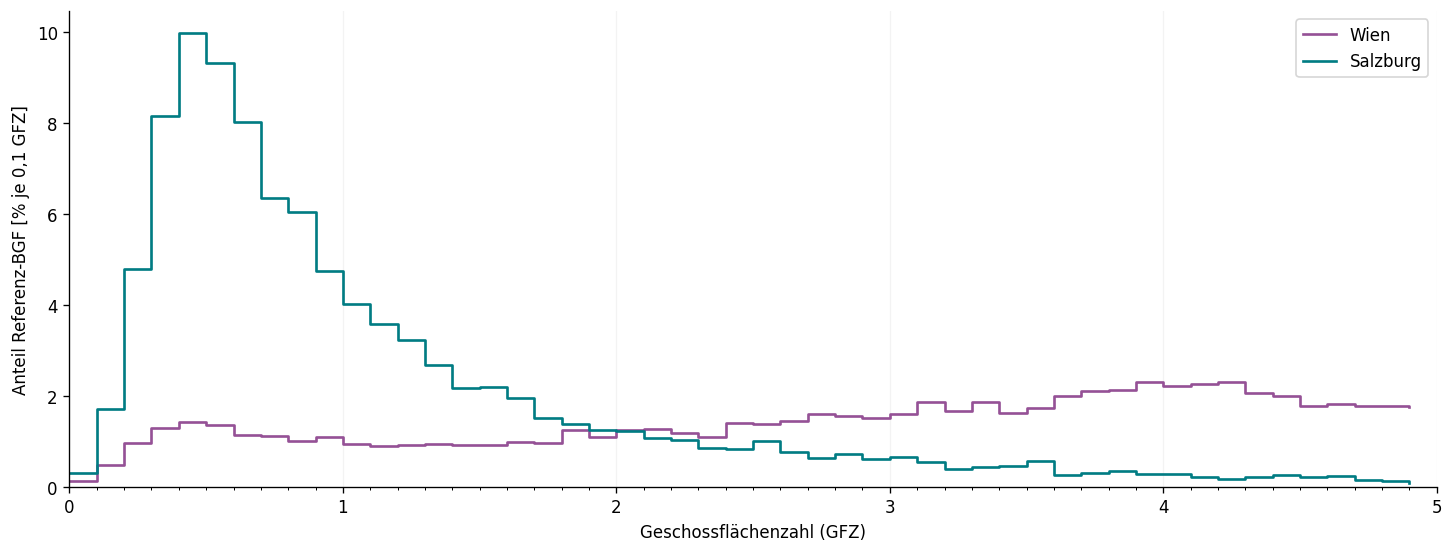

In [4]:
#| label: fig-gfz-rohstichproben
#| fig-cap: "BGF-gewichtete GFZ-Häufigkeit der bereinigten Referenzgebäude aus Wien und Salzburg. Das Histogramm beschreibt die Stichprobe, nicht die hochgerechnete österreichische BGF."
#| fig-width: 12
#| fig-height: 4.5
fig, ax = plt.subplots(figsize=(12, 4.5), layout="constrained")
raw_edges = np.arange(0, 5 + GFZ_STEP / 2, GFZ_STEP)
for region, color in [("Wien", "#955196"), ("Salzburg", "#007c83")]:
    g = samples.loc[samples.Bundesland == region]
    counts, _ = np.histogram(g.GFZ, bins=raw_edges, weights=g.BGF)
    # normiert auf die GESAMTE Referenz-BGF (einschließlich GFZ > 5)
    ax.step(raw_edges[:-1], 100 * counts / g.BGF.sum(), where="post",
            linewidth=1.6, label=region, color=color)
ax.set(xlim=(0, 5), ylim=(0, None), xlabel="Geschossflächenzahl (GFZ)",
       ylabel="Anteil Referenz-BGF [% je 0,1 GFZ]")
ax.xaxis.set_major_locator(MultipleLocator(1))
ax.xaxis.set_minor_locator(MultipleLocator(GFZ_STEP))
ax.grid(axis="x", alpha=.15)
ax.legend()
fig.savefig(OUT / "gfz_referenz_rohstichproben.png", dpi=180, bbox_inches="tight")
plt.show()

## 3. Statistische Bestandsdaten 2021: Herkunft, Flächen und Struktur

Für die nationale Hochrechnung bildet die Statistik die verbindliche **Mengenbasis**. Aus dem Tabellenblatt `python` werden die neun Bundesländer und sieben Geschossklassen mit den neun Nutzungsgruppen entnommen. Zusätzliche historische Aggregatzeilen („AT ohne Wien und Salzburg“, „Alles“) werden herausgenommen, damit keine Doppelzählung entsteht. Die nationale Zeile `AT` wird nur zur Kontrolle verwendet.

**Wichtig für die Diagramme:** Die statistischen Eingangsdaten sind als **NGF** abgelegt. Erst die Umrechnung mit `NGF_PER_BGF = 0.8` erzeugt die im Anschluss als **BGF** dargestellten Flächen. In den Diagrammen wird somit die *statistisch verankerte, modellierte BGF* gezeigt, nicht eine ursprünglich als BGF veröffentlichte Größe.

In [5]:
if STATISTICS.suffix.lower() == ".csv":
    stats_raw = pd.read_csv(STATISTICS, dtype={"GK": str}, low_memory=False)
else:
    stats_raw = pd.read_excel(STATISTICS, sheet_name="python", dtype={"GK": str})

missing = sorted(set(["NUTS", "GK", *USES]) - set(stats_raw.columns))
if missing:
    raise ValueError(f"Statistikdatei: Spalten fehlen: {missing}")

legacy_aggregates = ["AT ohne Wien und Salzburg", "Alles"]
removed_aggregates = stats_raw.loc[stats_raw.NUTS.isin(legacy_aggregates), "NUTS"].value_counts()
stats = stats_raw.loc[~stats_raw.NUTS.isin(legacy_aggregates), ["NUTS", "GK", *USES]].copy()
stats["GK"] = (stats["GK"].astype(str).str.strip().str.lower()
                .str.replace(r"\.0$", "", regex=True)
                .replace({"6 bis 10": "6-10", "6–10": "6-10", "6010": "6-10",
                          "6.0 bis 10.0": "6-10", "11 und mehr": "11+",
                          "11 oder mehr": "11+", "11plus": "11+"}))

bad_regions = set(stats.NUTS.dropna().astype(str)) - set(PROVINCES + ["AT"])
if bad_regions:
    raise ValueError(f"Unbekannte Regionen in Statistik: {bad_regions}")
if stats.duplicated(["NUTS", "GK"]).any():
    raise ValueError("Doppelte Statistikzeilen mit identischem NUTS/GK")
missing_pairs = {(b, g) for b in PROVINCES + ["AT"] for g in STOREYS} - set(zip(stats.NUTS, stats.GK))
if missing_pairs:
    raise ValueError(f"Geschossklassen in Statistik nicht vollständig: {sorted(missing_pairs)}")

for u in USES:
    stats[u] = pd.to_numeric(stats[u], errors="raise").fillna(0)
if stats[USES].lt(0).any().any():
    raise ValueError("Statistische NGF enthält negative Werte")

# Statistik: breites Eingangsschema in Bundesland × GK × Nutzung überführen
stats_long = stats.melt(id_vars=["NUTS", "GK"], value_vars=USES,
                        var_name="GWR_Nutzung", value_name="NGF_m2")
control_at = (stats_long.loc[stats_long.NUTS == "AT"]
              .set_index(["GK", "GWR_Nutzung"])["NGF_m2"])
provinces_ngf = stats_long.loc[stats_long.NUTS.isin(PROVINCES)].copy()
control_regions = provinces_ngf.groupby(["GK", "GWR_Nutzung"])["NGF_m2"].sum()
control_delta = control_regions.sub(control_at, fill_value=0)
if not np.allclose(control_delta.to_numpy(), 0, rtol=0, atol=0.01):
    raise AssertionError(f"Bundesländer ≠ AT-Zeile; Beispiele: {control_delta[control_delta.abs() > .01].head().to_dict()}")

# Der explizite Umrechnungsschritt: aus statistischer NGF wird Modell-BGF.
targets = provinces_ngf.rename(columns={"NUTS": "Bundesland"}).copy()
targets["BGF_target_m2"] = targets["NGF_m2"] / NGF_PER_BGF
print("Historische Summenzeilen ausgeschlossen:", removed_aggregates.to_dict())
print(f"AT-NGF nach Kontrollzeile: {control_at.sum()/1e6:,.3f} Mio. m²")
print(f"AT-BGF aus NGF/0,8: {targets.BGF_target_m2.sum()/1e6:,.3f} Mio. m²")
print(f"Maximale Differenz zur AT-Kontrollzeile: {control_delta.abs().max():.6f} m² NGF")

Historische Summenzeilen ausgeschlossen: {'AT ohne Wien und Salzburg': 7, 'Alles': 1}
AT-NGF nach Kontrollzeile: 847.148 Mio. m²
AT-BGF aus NGF/0,8: 1,058.935 Mio. m²
Maximale Differenz zur AT-Kontrollzeile: 0.000000 m² NGF


c:\Users\schneids\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
c:\Users\schneids\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


### Deskriptive Statistik des nationalen Bestandsmodells

Die erste Tabelle weist je Bundesland die NGF aus der Statistik, die daraus abgeleitete BGF und den Anteil an der nationalen Modell-BGF aus. Anschließend werden die Flächen nach Geschossklasse und Nutzung ausgewertet. Alle folgenden Flächenbalken verwenden die **gleichen neun Nutzungsfarben**, die später auch für die österreichische GFZ-Verteilung gelten. Ein gestapelter Balken zeigt die absoluten, summierbaren BGF-Beiträge, keine Gebäudeanzahlen.

In [6]:
stats_province = (targets.groupby("Bundesland", as_index=False)[["NGF_m2", "BGF_target_m2"]]
                  .sum().set_index("Bundesland").reindex(PROVINCES))
stats_province["Anteil_AT_%"] = 100 * stats_province.BGF_target_m2 / stats_province.BGF_target_m2.sum()
stats_display = stats_province.copy()
stats_display["NGF_Mio_m2"] = stats_display.NGF_m2 / 1e6
stats_display["BGF_Mio_m2"] = stats_display.BGF_target_m2 / 1e6
display(stats_display[["NGF_Mio_m2", "BGF_Mio_m2", "Anteil_AT_%"]].round(3))

stats_gk = (targets.groupby("GK")["BGF_target_m2"].sum()
            .reindex(STOREYS).div(1e6).rename("BGF_Mio_m2"))
stats_use = (targets.groupby("GWR_Nutzung")["BGF_target_m2"].sum()
             .reindex(PLOT_USE_ORDER).div(1e6).rename("BGF_Mio_m2"))
display(pd.DataFrame({"BGF Mio. m² nach Geschossklasse": stats_gk}))
display(pd.DataFrame({"BGF Mio. m² nach Hauptnutzung": stats_use}).sort_values("BGF Mio. m² nach Hauptnutzung", ascending=False))

,NGF_Mio_m2,BGF_Mio_m2,Anteil_AT_%
Bundesland,,,
Burgenland,30.434,38.043,3.593
Kärnten,54.446,68.058,6.427
Niederösterreich,171.910,214.888,20.293
Oberösterreich,157.719,197.149,18.618
Salzburg,55.595,69.494,6.563
Steiermark,120.031,150.038,14.169
Tirol,79.835,99.794,9.424
Vorarlberg,37.347,46.683,4.409
Wien,139.830,174.787,16.506


,BGF Mio. m² nach Geschossklasse
GK,
1,216.827551
2,382.613315
3,179.588949
4,104.302704
5,60.409821
6-10,103.898680
11+,11.293873


,BGF Mio. m² nach Hauptnutzung
GWR_Nutzung,
Ein- und Zweifamilienhäuser,375.776284
Mehrfamilienhaus,271.624840
Industrie und Lagerung,122.853401
Büronutzung,76.624895
"Kultur, Freizeit, Bildung und Gesundheit",65.894111
Groß- und Einzelhandelsgebäude,64.865034
Hotels o.Ä.,51.366923
Gemeinschaftsgebäude,17.056024
Verkehrs- und Nachrichtenwesen,12.873381


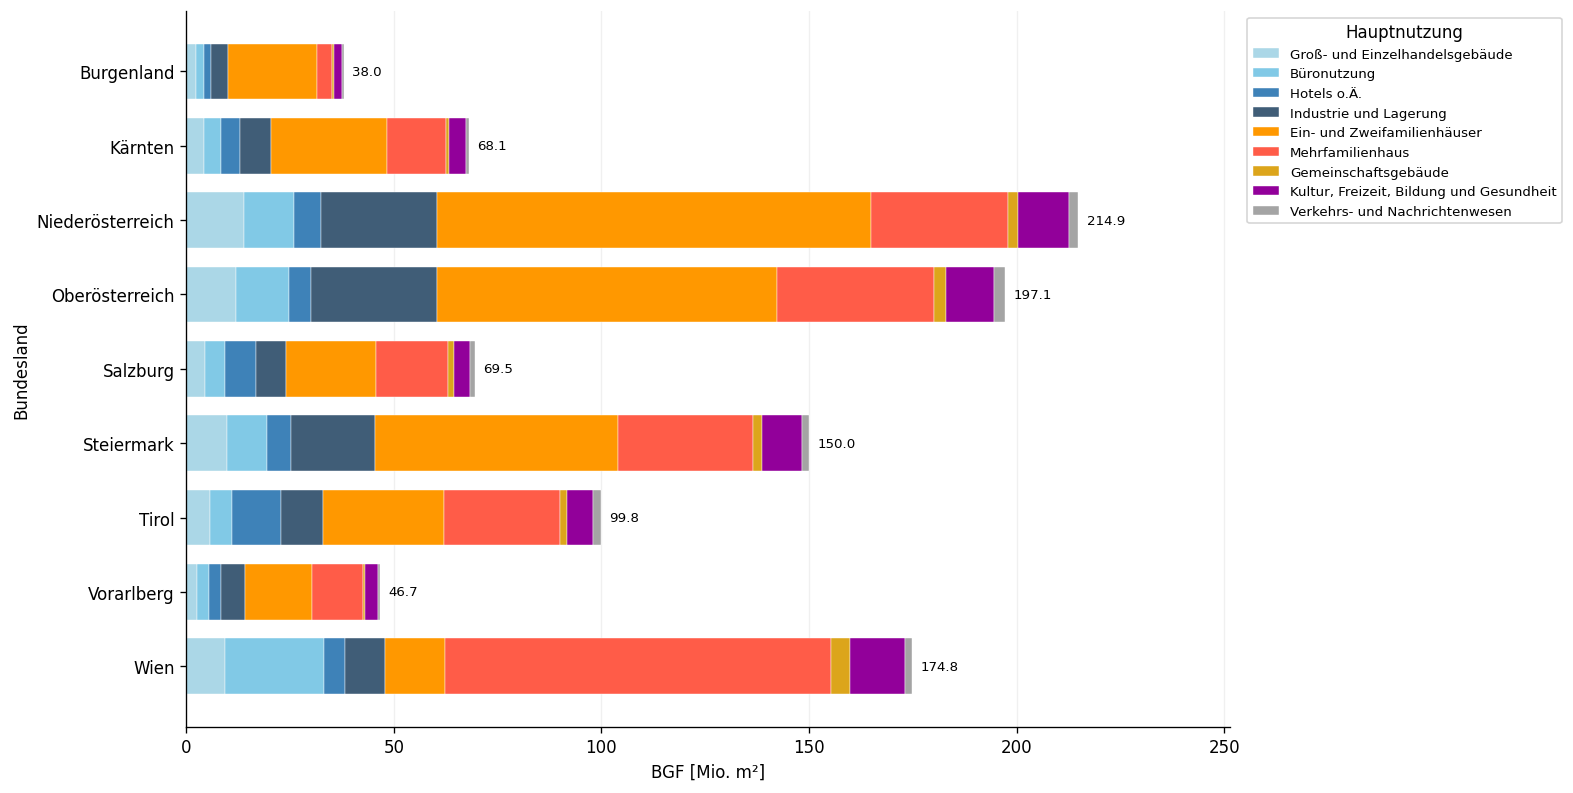

In [7]:
#| label: fig-gfz-statistik-bundesland
#| fig-cap: "Statistisch verankerte Bruttogrundfläche 2021 nach Bundesland und Gebäudehauptnutzung. Die BGF wird aus der statistischen NGF mit NGF/BGF = 0,8 abgeleitet; gestapelte Balken, absolute Flächen in Mio. m²."
#| fig-width: 13
#| fig-height: 6.5
# Statistische BGF nach Bundesland × Hauptnutzung (keine KDE beteiligt)
by_province_use = (targets.pivot_table(index="Bundesland", columns="GWR_Nutzung",
                values="BGF_target_m2", aggfunc="sum", fill_value=0)
            .reindex(index=PROVINCES, columns=PLOT_USE_ORDER, fill_value=0) / 1e6)
fig, ax = plt.subplots(figsize=(13, 6.5), layout="constrained")
left = np.zeros(len(PROVINCES))
for usage in PLOT_USE_ORDER:
    vals = by_province_use[usage].to_numpy()
    ax.barh(PROVINCES, vals, left=left, label=usage, color=COLORS[usage],
            height=.75, edgecolor="white", linewidth=.25)
    left += vals
# Gesamtsummen neben den Balken
for y, total in enumerate(left):
    ax.text(total + 2, y, f"{total:,.1f}", fontsize=8, va="center")
ax.set_xlim(0, max(left) * 1.17)
ax.set(xlabel="BGF [Mio. m²]", ylabel="Bundesland")
ax.invert_yaxis()
ax.grid(axis="x", alpha=.18)
ax.set_axisbelow(True)
ax.legend(title="Hauptnutzung", loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
fig.savefig(OUT / "gfz_statistik_bgf_bundeslaender.png", dpi=180, bbox_inches="tight")
plt.show()

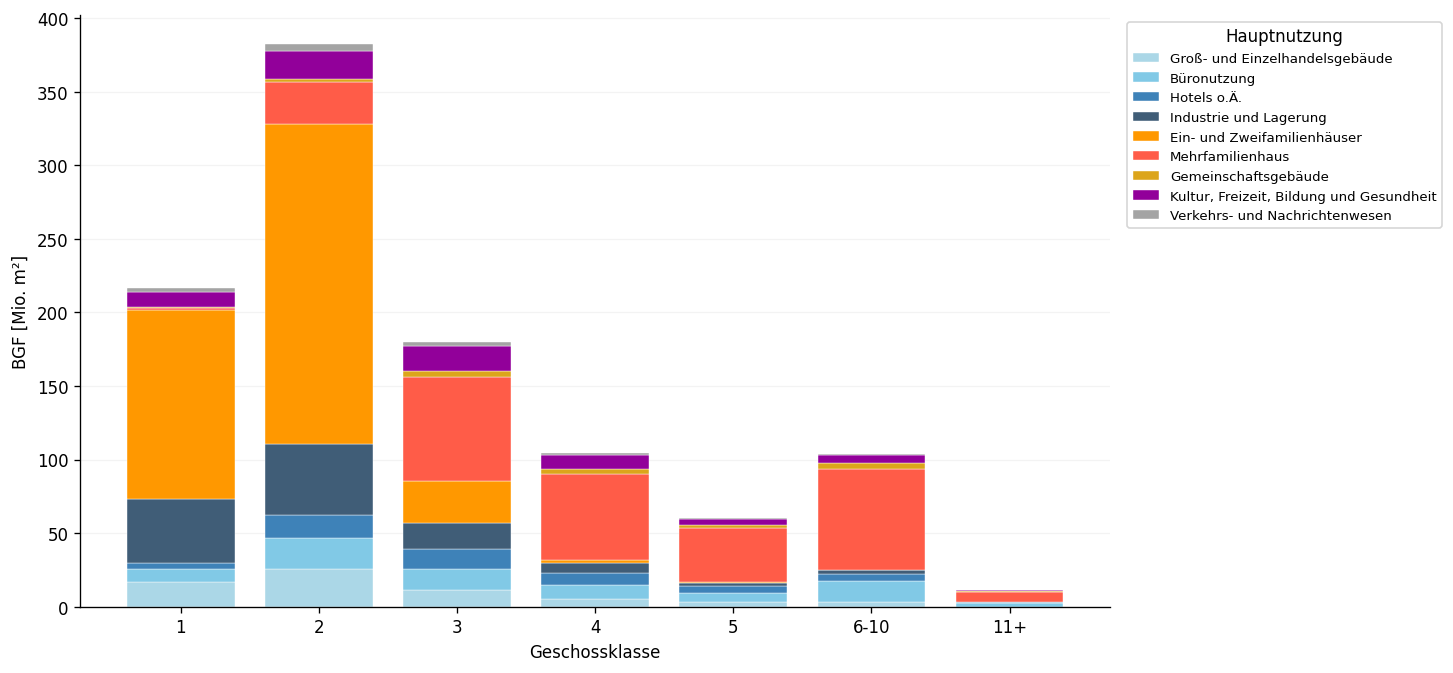

In [8]:
#| label: fig-gfz-statistik-geschosse
#| fig-cap: "Statistisch verankerte Bruttogrundfläche 2021 nach sieben Geschossklassen und Hauptnutzung, österreichweit. Jede Säule summiert die BGF aller neun Bundesländer der betreffenden Geschossklasse."
#| fig-width: 12
#| fig-height: 5.5
# Statistische BGF nach Geschossklasse × Hauptnutzung (keine GFZ-Modellierung beteiligt)
by_gk_use = (targets.pivot_table(index="GK", columns="GWR_Nutzung",
                values="BGF_target_m2", aggfunc="sum", fill_value=0)
           .reindex(index=STOREYS, columns=PLOT_USE_ORDER, fill_value=0) / 1e6)
fig, ax = plt.subplots(figsize=(12, 5.5), layout="constrained")
bottom = np.zeros(len(STOREYS))
for usage in PLOT_USE_ORDER:
    vals = by_gk_use[usage].to_numpy()
    ax.bar(STOREYS, vals, bottom=bottom, label=usage, color=COLORS[usage],
           edgecolor="white", linewidth=.25, width=.78)
    bottom += vals
ax.set(xlabel="Geschossklasse", ylabel="BGF [Mio. m²]")
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=.15)
ax.set_axisbelow(True)
ax.legend(title="Hauptnutzung", loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
fig.savefig(OUT / "gfz_statistik_bgf_geschosse.png", dpi=180, bbox_inches="tight")
plt.show()

## 4. Bestimmung der verfügbaren Referenzgruppen

Die Hochrechnung erfolgt für jede positive Kombination aus Bundesland, Geschossklasse und Hauptnutzung. Die statistische Fläche der Zielkombination wird unverändert übernommen. Zur Ermittlung ihrer Dichteverteilung wird jeweils eine gebäudescharfe **Referenzgruppe** ausgewählt:

1. Für Wien: gleiche Nutzung und Geschossklasse aus Wien. Für die übrigen Bundesländer: gleiche Nutzung und Geschossklasse aus Salzburg.
2. Sind weniger als fünf Gebäude verfügbar: gleiche Nutzung und Geschossklasse aus Wien (sofern ausreichend belegt).
3. Falls weiterhin unzureichend: gleiche Nutzung aus einer **nächstgelegenen Geschossklasse**, zuerst in der vorgesehenen Referenzregion, dann in Wien. Die Auswahl erfolgt anhand des Indexabstands der sieben Geschossklassen; die Klassenfolge ist oben definiert.

Jede Ersatzzuordnung wird als eigener Status und mit ihrer Referenzregion/-geschossklasse protokolliert. Wenn keine ausreichend große Referenzstichprobe gefunden wird, bricht die Rechnung ab. Die Ersatzregel für diesen Arbeitsstand ist freigegeben; sie ist keine zusätzliche statistische Messung.

In [9]:
# Explizite Zuordnung je positiver Bundesland/GK/Nutzung-Zielkombination
reference_groups = {
    key: group for key, group in samples.groupby(["Bundesland", "GK", "GWR_Nutzung"], sort=False)
}
coverage_rows = []
for row in targets.itertuples(index=False):
    if row.BGF_target_m2 <= 0:
        continue
    primary_region = "Wien" if row.Bundesland == "Wien" else "Salzburg"
    primary = (primary_region, row.GK, row.GWR_Nutzung)
    primary_n = len(reference_groups.get(primary, ()))
    source, status = None, None
    if primary_n >= MIN_SAMPLES:
        source, status = primary, "reference-exact"
    else:
        if FALLBACK == "error":
            raise ValueError(f"Nicht ausreichende Referenzgruppe: {primary}, n={primary_n}")
        vienna_exact = ("Wien", row.GK, row.GWR_Nutzung)
        if len(reference_groups.get(vienna_exact, ())) >= MIN_SAMPLES:
            source, status = vienna_exact, "fallback-vienna-exact"
        else:
            # Gleiche Hauptnutzung, minimale Distanz der Geschossklassen
            for candidate_region in dict.fromkeys([primary_region, "Wien"]):
                candidates = [
                    (abs(STOREYS.index(row.GK) - STOREYS.index(other_gk)), other_gk)
                    for other_gk in STOREYS
                    if len(reference_groups.get((candidate_region, other_gk, row.GWR_Nutzung), ())) >= MIN_SAMPLES
                ]
                if candidates:
                    _, nearest_gk = min(candidates)
                    source = (candidate_region, nearest_gk, row.GWR_Nutzung)
                    status = f"fallback-{candidate_region.lower()}-nearest-storey"
                    break
        if source is None:
            raise ValueError(f"Keine gültige Referenz für {row.Bundesland}/{row.GK}/{row.GWR_Nutzung}")

    coverage_rows.append({
        "Bundesland": row.Bundesland, "GK": row.GK, "GWR_Nutzung": row.GWR_Nutzung,
        "NGF_m2": row.NGF_m2, "BGF_target_m2": row.BGF_target_m2,
        "primary_region": primary_region, "primary_n": primary_n,
        "reference_region": source[0], "reference_gk": source[1],
        "status": status, "n_reference_buildings": len(reference_groups[source]),
    })
coverage = pd.DataFrame(coverage_rows)
print("Positive statistische Zielkombinationen:", len(coverage))
print("Unmittelbare Referenzen:", int((coverage.status == "reference-exact").sum()))
print("Ersatzreferenzen:", int((coverage.status != "reference-exact").sum()))
display(coverage.groupby("status").agg(Kombinationen=("status", "size"),
                    BGF_Mio_m2=("BGF_target_m2", lambda s: s.sum() / 1e6)).round(3))
display(coverage.loc[coverage.status != "reference-exact", ["Bundesland", "GK", "GWR_Nutzung",
               "primary_n", "reference_region", "reference_gk", "n_reference_buildings", "status"]].head(30))

Positive statistische Zielkombinationen: 516
Unmittelbare Referenzen: 425
Ersatzreferenzen: 91


,Kombinationen,BGF_Mio_m2
status,,
fallback-salzburg-nearest-storey,3,0.066
fallback-vienna-exact,84,17.362
fallback-wien-nearest-storey,4,0.532
reference-exact,425,1040.974


,Bundesland,GK,GWR_Nutzung,primary_n,reference_region,reference_gk,n_reference_buildings,status
24,Oberösterreich,11+,Hotels o.Ä.,0,Wien,11+,20,fallback-vienna-exact
43,Tirol,11+,Hotels o.Ä.,0,Wien,11+,20,fallback-vienna-exact
50,Vorarlberg,11+,Hotels o.Ä.,0,Wien,11+,20,fallback-vienna-exact
70,Kärnten,11+,Büronutzung,0,Wien,11+,103,fallback-vienna-exact
77,Niederösterreich,11+,Büronutzung,0,Wien,11+,103,fallback-vienna-exact
84,Oberösterreich,11+,Büronutzung,0,Wien,11+,103,fallback-vienna-exact
97,Steiermark,11+,Büronutzung,0,Wien,11+,103,fallback-vienna-exact
104,Tirol,11+,Büronutzung,0,Wien,11+,103,fallback-vienna-exact
142,Oberösterreich,11+,Groß- und Einzelhandelsgebäude,0,Salzburg,6-10,47,fallback-salzburg-nearest-storey
161,Tirol,11+,Groß- und Einzelhandelsgebäude,0,Salzburg,6-10,47,fallback-salzburg-nearest-storey


## 5. BGF-gewichtete Kerndichteschätzung auf dem GFZ-Raster

Für eine Referenzgruppe $r$ mit Gebäuden $i$ bildet die Kerndichteschätzung die Verteilung der GFZ **flächengewichtet** ab. Das Gewicht des Einzelgebäudes ist seine BGF $w_i=A_{\mathrm{BGF},i}$. Für die KDE wird die Scott-Bandbreite (`scipy.stats.gaussian_kde`, `bw_method="scott"`) verwendet.

Die Funktion wird an gleich breiten **Klassenmitten** ausgewertet: $d_j=(j+0{,}5)\Delta d$, $\Delta d=0{,}1$, $0\le d<20$. Aus den dort berechneten Dichtewerten $\hat f_r(d_j)$ entstehen diskrete Massen:

$$p_{r,j}=\frac{\hat f_r(d_j)}{\sum_k\hat f_r(d_k)},\qquad\sum_j p_{r,j}=1.$$

Die diskrete Normalisierung stellt sicher, dass die nachfolgende Zuordnung **flächenbilanztreu** ist. Wegen der Normierung auf ein begrenztes Raster ist dies keine von Grenz- bzw. Bandbreiteneffekten freie Schätzung. Bei identischen GFZ-Werten innerhalb einer ansonsten ausreichend großen Gruppe wird anstelle der singulären KDE ein BGF-gewichtetes Histogramm im gleichen Raster verwendet und entsprechend als solches gekennzeichnet.

In [10]:
# Jedes Rasterelement vertritt das Intervall [j*0,1 ; (j+1)*0,1)
nbins = int(round(GFZ_MAX / GFZ_STEP))
gfz_centers = (np.arange(nbins) + .5) * GFZ_STEP
bin_edges = np.r_[gfz_centers[0] - GFZ_STEP/2, gfz_centers + GFZ_STEP/2]

# Einmalige KDE je wirklich verwendeter Referenz (wiederholte Referenzen teilen sich die Kurve)
source_keys = coverage[["reference_region", "reference_gk", "GWR_Nutzung"]].drop_duplicates()
probability_cache = {}
estimator_cache = {}
for source_row in source_keys.itertuples(index=False):
    key = (source_row.reference_region, source_row.reference_gk, source_row.GWR_Nutzung)
    source_data = reference_groups[key]
    x_gfz = source_data.GFZ.to_numpy(dtype=float)
    area_weight = source_data.BGF.to_numpy(dtype=float)
    if METHOD == "histogram" or len(np.unique(x_gfz)) < 2:
        unnormalized, _ = np.histogram(x_gfz, bins=bin_edges, weights=area_weight)
        estimator_cache[key] = "bgf-weighted-histogram"
    else:
        kde = gaussian_kde(x_gfz, weights=area_weight, bw_method="scott")
        unnormalized = kde(gfz_centers)
        estimator_cache[key] = "bgf-weighted-kde-scott"
    if not np.isfinite(unnormalized).all() or unnormalized.sum() <= 0:
        raise ValueError(f"Dichteschätzung unbrauchbar: {key}")
    p = unnormalized / unnormalized.sum()
    if (p < 0).any() or not np.isclose(p.sum(), 1, atol=1e-9):
        raise AssertionError(f"KDE-Massen nicht korrekt normiert: {key}")
    probability_cache[key] = p

print("Eigenständige Referenzverteilungen:", len(probability_cache))
print(pd.Series(estimator_cache).value_counts().to_string())

Eigenständige Referenzverteilungen: 106
bgf-weighted-kde-scott    106


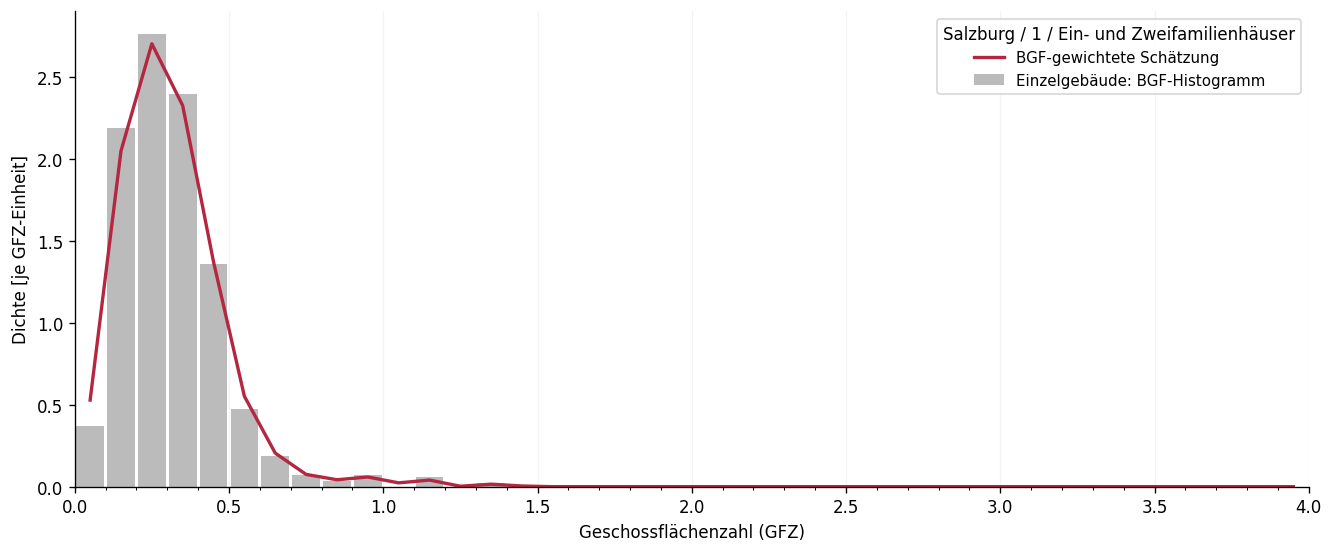

In [11]:
#| label: fig-gfz-kde-beispiel
#| fig-cap: "Beispiel der BGF-gewichteten Dichteschätzung für eine Referenzgruppe: Histogramm der Einzelgebäude und auf GFZ 0–20 normierte KDE bzw. Histogramm-Ersatzschätzung. Die Darstellung dient der methodischen Nachvollziehbarkeit."
#| fig-width: 11
#| fig-height: 4.5
# Möglichst anschauliche Beispielgruppe auswählen, ansonsten erste verfügbare Quelle
example_key = ("Salzburg", "1", "Ein- und Zweifamilienhäuser")
if example_key not in probability_cache:
    example_key = next(iter(probability_cache))
example = reference_groups[example_key]
hist_area, _ = np.histogram(example.GFZ, bins=bin_edges, weights=example.BGF)
hist_density = hist_area / hist_area.sum() / GFZ_STEP
fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
view = gfz_centers <= 4
ax.bar(gfz_centers[view], hist_density[view], width=GFZ_STEP*.9,
       color="#bbbbbb", label="Einzelgebäude: BGF-Histogramm")
ax.plot(gfz_centers[view], probability_cache[example_key][view] / GFZ_STEP,
        color="#b52640", linewidth=2, label="BGF-gewichtete Schätzung")
ax.set(xlim=(0, 4), ylim=(0, None), xlabel="Geschossflächenzahl (GFZ)",
       ylabel="Dichte [je GFZ-Einheit]")
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(GFZ_STEP))
ax.grid(axis="x", alpha=.15)
ax.legend(title=" / ".join(example_key), fontsize=9)
fig.savefig(OUT / "gfz_kde_beispiel.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Hochrechnung: statistische BGF × Dichtemasse

Jede positive Zielkombination $c=(b,g,u)$ besitzt eine aus der Statistik abgeleitete BGF $A_c$ und eine oben ausgewählte Referenzkurve $r(c)$. Für jede GFZ-Klasse $j$ wird ihr Flächenbeitrag berechnet:

$$ A_{c,j}=A_c\,p_{r(c),j}. $$

Wegen $\sum_j p_{r(c),j}=1$ gilt **$\sum_j A_{c,j}=A_c$** für jede einzelne Zielkombination. Die Summe über alle neun Bundesländer liefert die österreichische GFZ-Verteilung nach Hauptnutzung:

$$A_{\mathrm{AT},u,j}=\sum_b\sum_g A_{b,g,u,j}. $$

Die Referenzgruppen verändern somit die Verteilung *innerhalb* der statistischen Zielgruppen, aber **nicht** deren Flächensummen. Gerade diese Unterscheidung zwischen Stichprobeninformation und statistischer Flächenmenge ist das Prinzip der bundeslandweisen Hochrechnung.

In [12]:
# In jeder Zielzelle dieselbe normierte Referenzmasse, aber andere statistische Fläche
allocation_blocks = []
audit_rows = []
for target in coverage.itertuples(index=False):
    ref = (target.reference_region, target.reference_gk, target.GWR_Nutzung)
    probabilities = probability_cache[ref]
    allocated_bgf = target.BGF_target_m2 * probabilities
    cell_id = f"{target.Bundesland}|{target.GK}|{target.GWR_Nutzung}"
    allocation_blocks.append(pd.DataFrame({
        "cell_id": cell_id, "Bundesland": target.Bundesland, "GK": target.GK,
        "GWR_Nutzung": target.GWR_Nutzung, "GFZ": np.round(gfz_centers, 10),
        "BGF_m2": allocated_bgf,
    }))
    audit_rows.append({
        "cell_id": cell_id, "Bundesland": target.Bundesland, "GK": target.GK,
        "GWR_Nutzung": target.GWR_Nutzung, "BGF_target_m2": target.BGF_target_m2,
        "BGF_allocated_m2": float(allocated_bgf.sum()),
        "delta_m2": float(allocated_bgf.sum() - target.BGF_target_m2),
        "reference_region": target.reference_region, "reference_gk": target.reference_gk,
        "status": target.status, "n_reference_buildings": target.n_reference_buildings,
        "estimate_method": estimator_cache[ref],
        "expected_gfz": float(np.dot(gfz_centers, probabilities)),
    })

# Gruppen mit Null-Masse nicht als eigene CSV-Zeilen ausgeben (wie in gfz_hydrator)
detail = pd.concat(allocation_blocks, ignore_index=True)
detail = detail.loc[detail.BGF_m2 > 0].copy()
audit = pd.DataFrame(audit_rows)

# Alle späteren Ergebnisdiagramme basieren auf DIESEN hier berechneten Tabellen.
at_by_use = detail.groupby(["GFZ", "GWR_Nutzung"], as_index=False).BGF_m2.sum()
by_province = detail.groupby(["Bundesland", "GFZ"], as_index=False).BGF_m2.sum()
at_by_gk_use = detail.groupby(["GK", "GWR_Nutzung", "GFZ"], as_index=False).BGF_m2.sum()
print(f"Berechnete GFZ-Zuordnungen: {len(detail):,} Zeilen")

Berechnete GFZ-Zuordnungen: 83,703 Zeilen


## 7. Kontrollrechnungen und Abdeckung

Die Flächenbilanz wird auf **drei Ebenen** geprüft: jede Zielkombination, Gesamtsumme der neun Bundesländer und nationale Statistik-Kontrollzeile `AT`. Ersatzschätzungen werden sowohl nach *Anzahl* der betroffenen Kombinationen als auch nach ihrem *BGF-Anteil* ausgewiesen. Hohe Zahlen kleiner Ersatzgruppen können einen niedrigen Flächenanteil haben.

In [13]:
# Flächenerhaltung pro Zelle und landesweit
assert np.allclose(audit.BGF_allocated_m2, audit.BGF_target_m2,
                   rtol=1e-12, atol=1e-5), "Fehler bei einer statistischen Zielgruppe"
national_target = float(targets.BGF_target_m2.sum())
national_allocated = float(detail.BGF_m2.sum())
assert np.isclose(national_allocated, national_target, rtol=1e-12, atol=1e-4), "Nationale BGF-Bilanz fehlerhaft"
assert np.isclose(national_target, control_at.sum()/NGF_PER_BGF, atol=0.02, rtol=0)

fallback_mask = audit.status != "reference-exact"
fallback_area = float(audit.loc[fallback_mask, "BGF_target_m2"].sum())
print(f"Statistische Ziel-BGF Österreich: {national_target / 1e6:,.3f} Mio. m²")
print(f"Verteilte BGF Österreich:        {national_allocated / 1e6:,.3f} Mio. m²")
print(f"Bilanzdifferenz:                 {national_allocated - national_target:.9f} m²")
print(f"Max. Betrag je Zelle:           {audit.delta_m2.abs().max():.9f} m²")
print(f"Kombinationen:                  {len(audit)}")
print(f"Ersatzreferenzen:                {fallback_mask.sum()} ({100*fallback_mask.mean():.2f} % der Kombinationen)")
print(f"BGF-Anteil der Ersatzreferenzen: {100*fallback_area/national_target:.3f} %")

land_area = (detail.groupby("Bundesland").BGF_m2.sum().reindex(PROVINCES))
land_target = (targets.groupby("Bundesland").BGF_target_m2.sum().reindex(PROVINCES))
assert np.allclose(land_area, land_target, rtol=1e-12, atol=1e-4)

# Gewichteter Mittelwert der modellierten GFZ: kein nationales BGF/Grundstücksfläche-Verhältnis
mean_gfz = float(np.dot(detail.GFZ, detail.BGF_m2) / national_allocated)
print(f"Flächengewichtete mittlere Modell-GFZ: {mean_gfz:.3f}")

Statistische Ziel-BGF Österreich: 1,058.935 Mio. m²
Verteilte BGF Österreich:        1,058.935 Mio. m²
Bilanzdifferenz:                 -0.000000119 m²
Max. Betrag je Zelle:           0.000000015 m²
Kombinationen:                  516
Ersatzreferenzen:                91 (17.64 % der Kombinationen)
BGF-Anteil der Ersatzreferenzen: 1.696 %
Flächengewichtete mittlere Modell-GFZ: 1.231


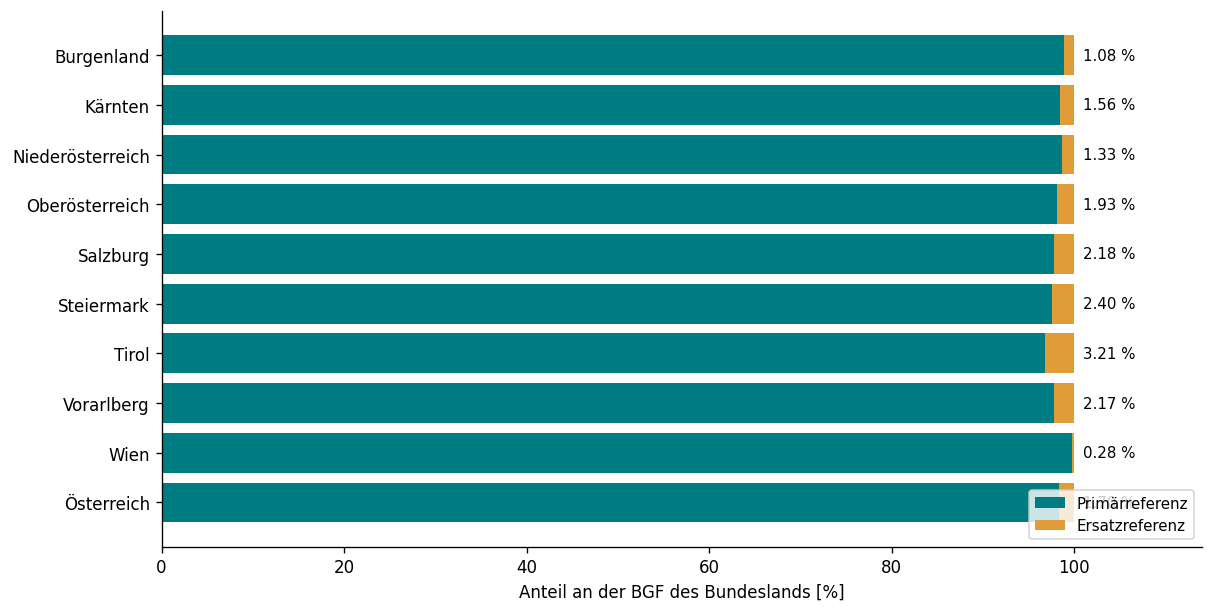

In [14]:
#| label: fig-gfz-ersatzanteile
#| fig-cap: "BGF-Abdeckung der primären Referenzen und expliziten Ersatzschätzungen nach Bundesland. Die Balken zeigen Anteile der jeweiligen statistischen Landes-BGF, nicht Anteile der Gebäudefälle."
#| fig-width: 10
#| fig-height: 5
fall_by_land = (audit.assign(fallback_BGF_m2=np.where(fallback_mask, audit.BGF_target_m2, 0))
    .groupby("Bundesland")[["BGF_target_m2", "fallback_BGF_m2"]].sum().reindex(PROVINCES))
fall_by_land.loc["Österreich"] = fall_by_land.sum()
fall_share = 100 * fall_by_land.fallback_BGF_m2 / fall_by_land.BGF_target_m2
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
ax.barh(fall_share.index, 100 - fall_share, color="#007c83", label="Primärreferenz")
ax.barh(fall_share.index, fall_share, left=100-fall_share,
        color="#df9c38", label="Ersatzreferenz")
for y, share in enumerate(fall_share):
    ax.text(101, y, f"{share:.2f} %", va="center", fontsize=9)
ax.set(xlim=(0, 114), xlabel="Anteil an der BGF des Bundeslands [%]")
ax.invert_yaxis()
ax.legend(loc="lower right", fontsize=9)
fig.savefig(OUT / "fallback_bundeslaender.png", dpi=180, bbox_inches="tight")
plt.show()

## 8. Modellierte österreichische GFZ-Verteilung

Die Abbildung zeigt die aus der Statistik hochgerechnete BGF je **GFZ-Intervall von 0,1**, aufgeteilt auf die neun Hauptnutzungen. Die Darstellung ist eine gestapelte Balkengrafik (kein Dichteplot): die Höhe eines Balkens ist die Summe von Mio. m² BGF in dieser GFZ-Klasse. Das sichtbare GFZ-Fenster kann ohne Neuberechnung verändert werden; alle Klassen bis GFZ 20 bleiben in der Flächenbilanz erhalten.

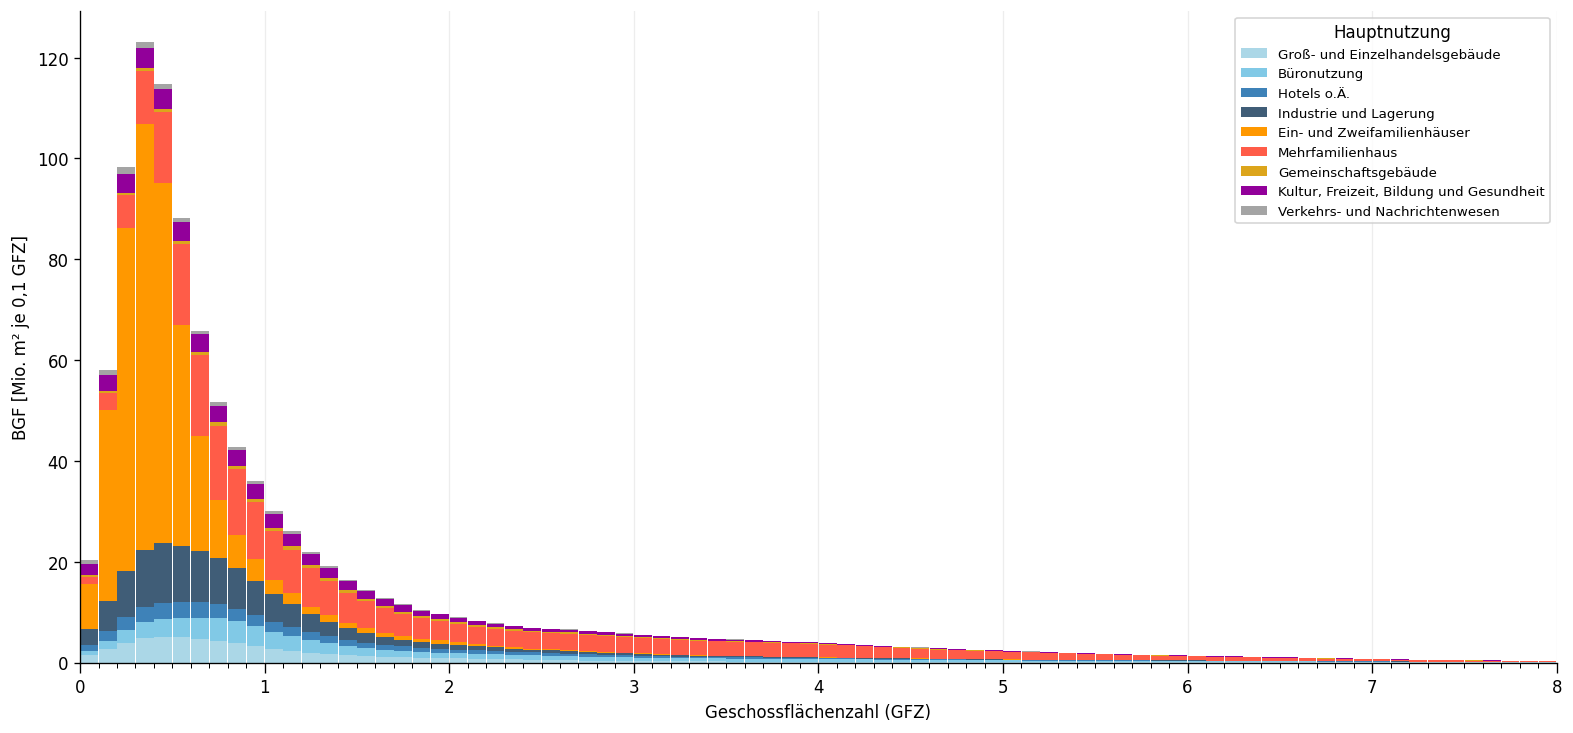

Außerhalb des Darstellungsfensters GFZ > 8: 0.500 % der AT-BGF; in Bilanz enthalten.


In [15]:
#| label: fig-gfz-oesterreich
#| fig-cap: "Modellierte österreichische BGF-Verteilung 2021 nach Hauptnutzung (gestapelte 0,1-GFZ-Balken). Die Berechnung erfolgt bis GFZ 20; ein gegebenenfalls abgeschnittener Anteil ist im Text unter der Grafik ausgewiesen."
#| fig-width: 13
#| fig-height: 6
wide = (at_by_use.pivot_table(index="GFZ", columns="GWR_Nutzung",
           values="BGF_m2", aggfunc="sum", fill_value=0)
        .reindex(columns=PLOT_USE_ORDER, fill_value=0).sort_index() / 1e6)
view = wide.loc[wide.index <= PLOT_GFZ_MAX]
fig, ax = plt.subplots(figsize=(13, 6), layout="constrained")
bottom = np.zeros(len(view))
for use in PLOT_USE_ORDER:
    v = view[use].to_numpy()
    ax.bar(view.index.to_numpy(), v, width=GFZ_STEP * .96,
           align="center", bottom=bottom, color=COLORS[use],
           edgecolor="none", label=use)
    bottom += v
ax.set(xlim=(0, PLOT_GFZ_MAX), ylim=(0, None),
       xlabel="Geschossflächenzahl (GFZ)", ylabel="BGF [Mio. m² je 0,1 GFZ]")
ax.xaxis.set_major_locator(MultipleLocator(1.0))
ax.xaxis.set_minor_locator(MultipleLocator(GFZ_STEP))
ax.tick_params(axis="x", which="major", length=6)
ax.tick_params(axis="x", which="minor", length=3)
ax.set_axisbelow(True)
ax.grid(axis="x", which="major", alpha=.22)
ax.legend(title="Hauptnutzung", loc="upper right", fontsize=8, title_fontsize=10)
fig.savefig(OUT / "gfz_oesterreich_nutzung.png", dpi=180, bbox_inches="tight")
plt.show()

share_beyond = 100 * wide.loc[wide.index > PLOT_GFZ_MAX].to_numpy().sum() / wide.to_numpy().sum()
print(f"Außerhalb des Darstellungsfensters GFZ > {PLOT_GFZ_MAX:g}: {share_beyond:.3f} % der AT-BGF; in Bilanz enthalten.")

### Kerndichteprofile nach Geschossklasse und Hauptnutzung

Zur Überprüfung der angewendeten Dichteformen können die BGF-Anteile *innerhalb* jeder Kombination aus Geschossklasse und Hauptnutzung wieder auf 1 normiert werden. Daraus entsteht eine Matrix von flächengewichteten Dichteprofilen. **Diese Kurven sind anders normiert als die absoluten BGF-Balken** und dürfen nicht als Mio. m² interpretiert werden. Alle Geschossklassen, für die kein statistischer Flächenanteil vorliegt, bleiben leer.

Die roten senkrechten Markierungen zeigen bei eindeutig benannten Geschossklassen nur den Zahlenwert der Geschosszahl als Orientierung an. Sie sind **keine geprüften physikalischen GFZ-Obergrenzen**. Bei „11+“ gibt es keine einzelne Obergrenze.

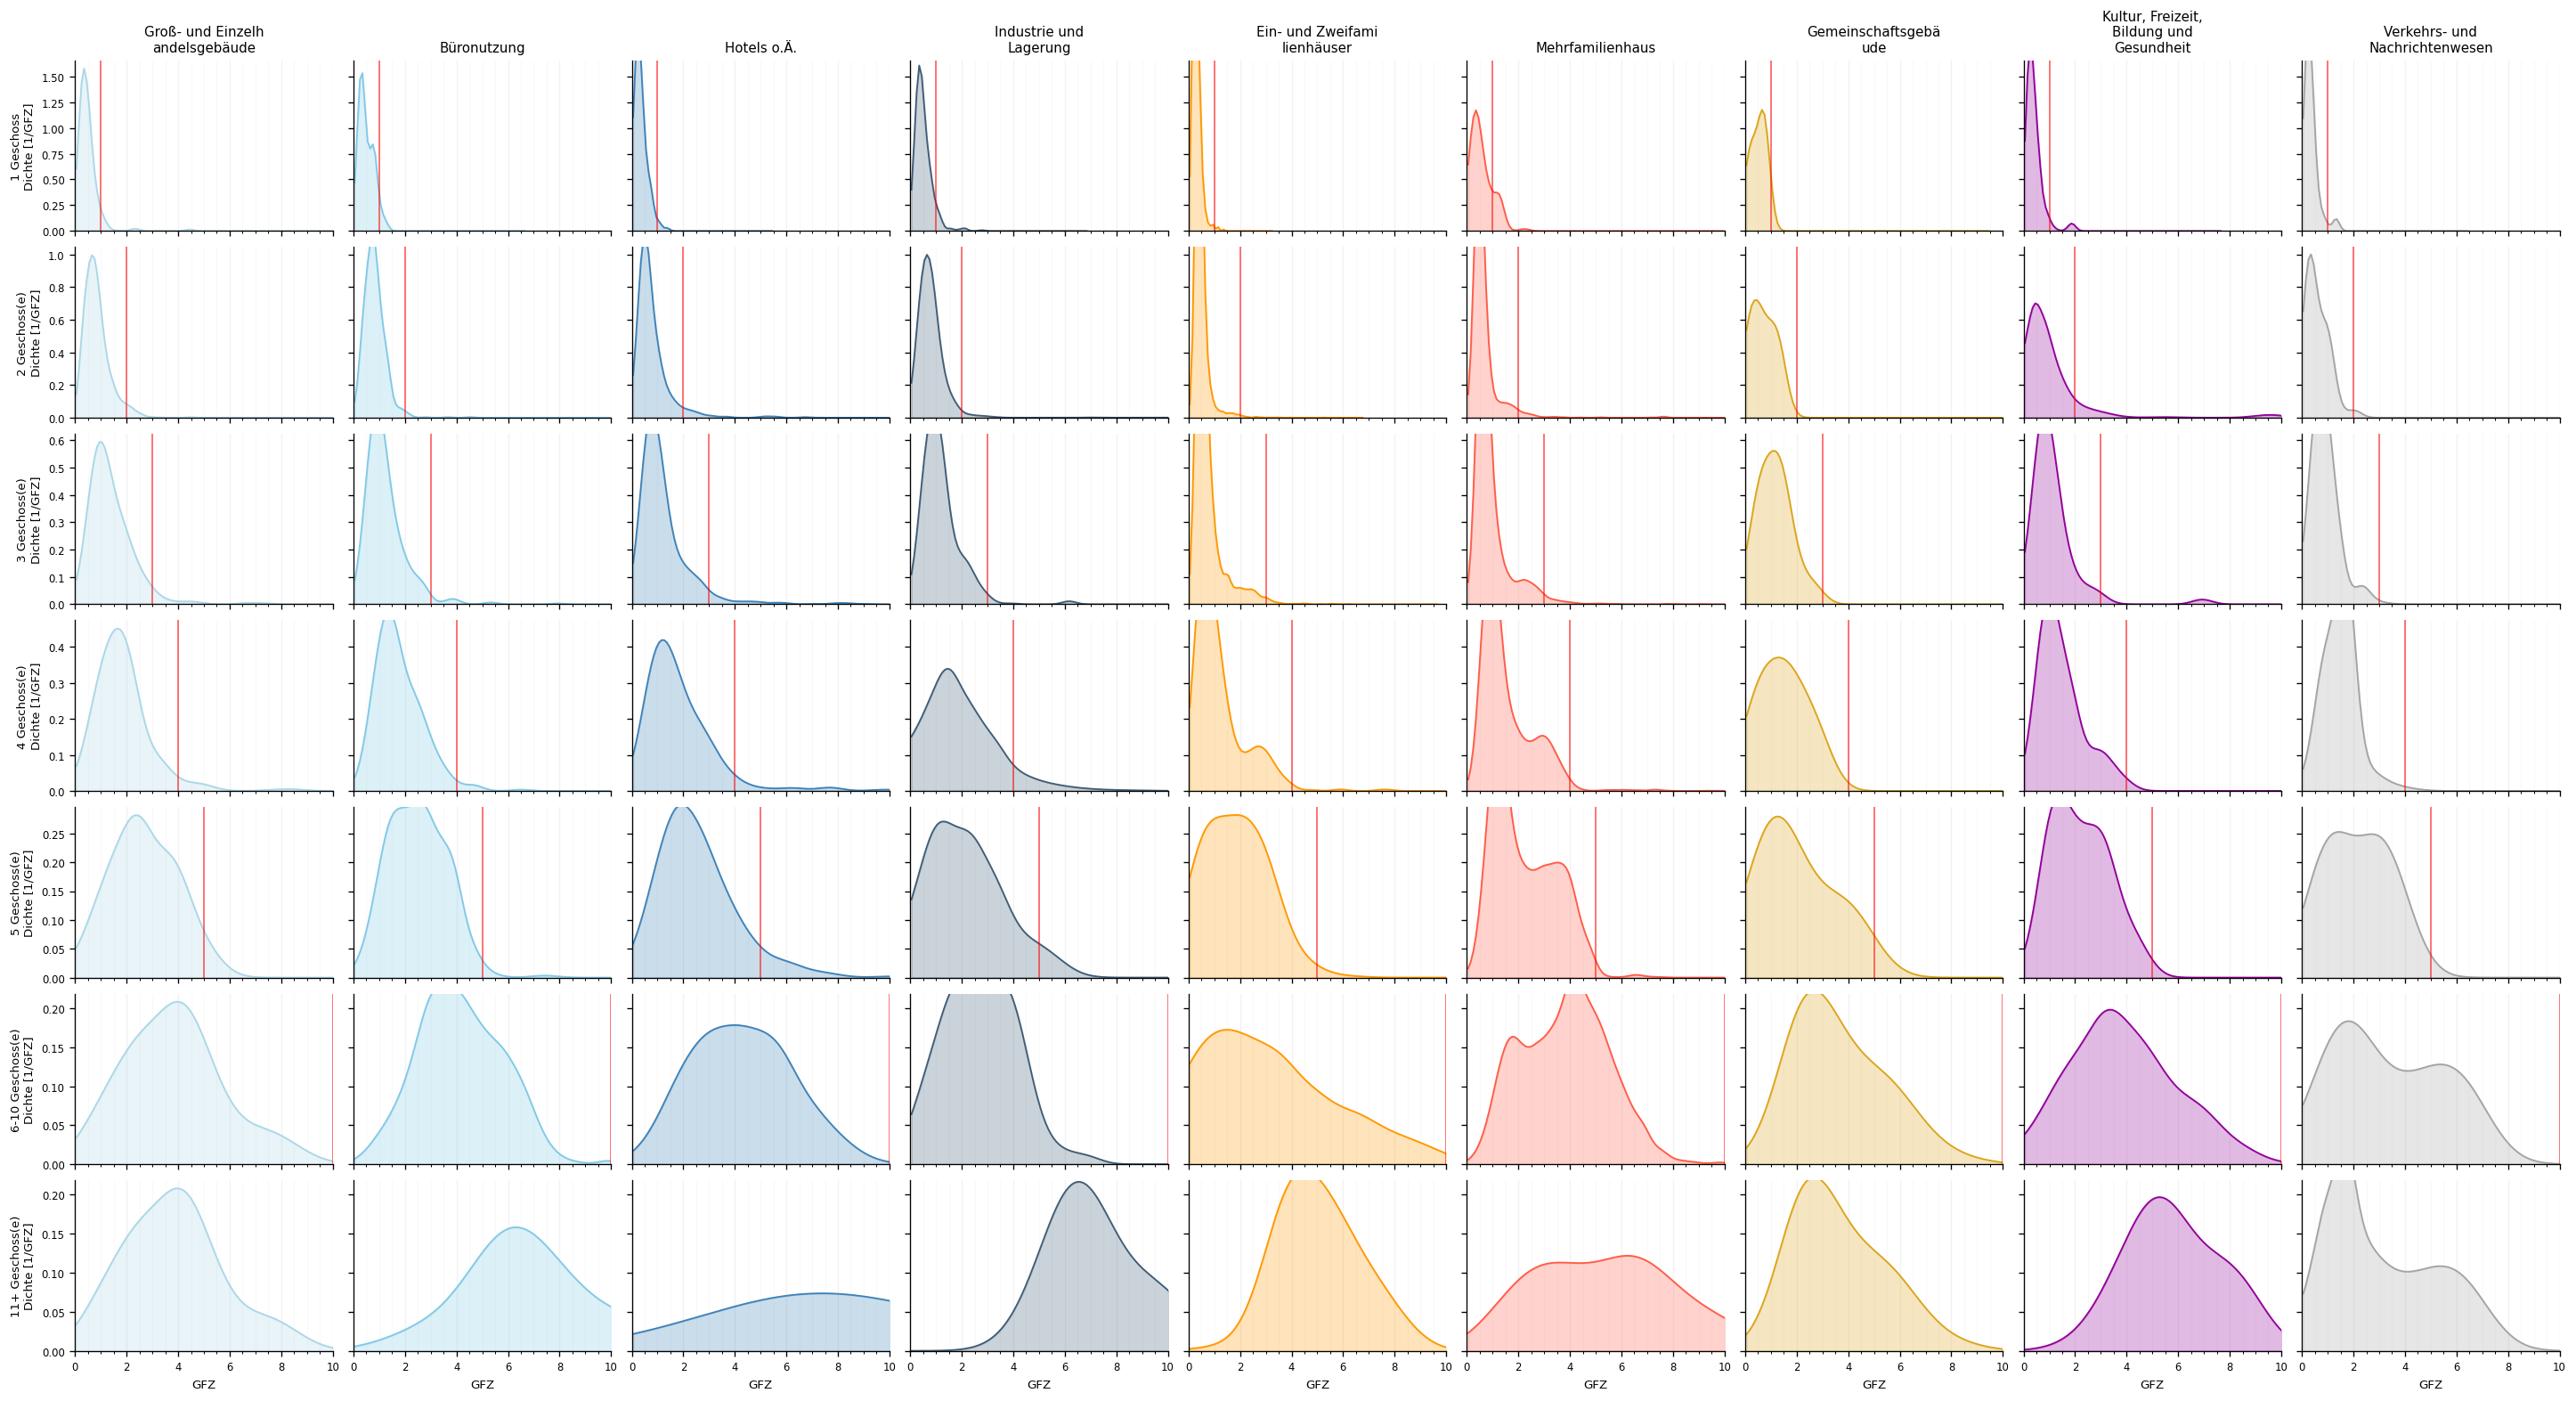

In [16]:
#| label: fig-gfz-kde-matrix
#| fig-cap: "Flächengewichtete modellierte GFZ-Dichteprofile Österreichs, normiert innerhalb jeder Geschossklassen-/Nutzungskombination (7 × 9). Rote Linien: Geschosszahl als Orientierung, nicht als verbindliche GFZ-Grenze."
#| fig-width: 24
#| fig-height: 13
fig, axes = plt.subplots(len(STOREYS), len(PLOT_USE_ORDER),
                         figsize=(24, 13), sharex=True, sharey="row", layout="constrained")
for i, gk in enumerate(STOREYS):
    for j, use in enumerate(PLOT_USE_ORDER):
        ax = axes[i, j]
        one = at_by_gk_use.loc[(at_by_gk_use.GK == gk) &
                               (at_by_gk_use.GWR_Nutzung == use)].sort_values("GFZ")
        if not one.empty and one.BGF_m2.sum() > 0:
            density = one.BGF_m2.to_numpy() / one.BGF_m2.sum() / GFZ_STEP
            ax.plot(one.GFZ, density, color=COLORS[use], linewidth=1.1)
            ax.fill_between(one.GFZ, 0, density, color=COLORS[use], alpha=.27)
        marker = 10 if gk == "6-10" else (int(gk) if gk.isdigit() else None)
        if marker is not None:
            ax.axvline(marker, color="red", linewidth=.9, alpha=.7)
        ax.set_xlim(0, 10)
        ax.set_ylim(bottom=0)
        ax.xaxis.set_major_locator(MultipleLocator(2))
        ax.xaxis.set_minor_locator(MultipleLocator(.5))
        ax.grid(axis="x", which="major", alpha=.16)
        ax.grid(axis="x", which="minor", alpha=.07)
        ax.set_axisbelow(True)
        ax.tick_params(axis="both", labelsize=7)
        if i == 0:
            ax.set_title(textwrap.fill(use, 17), fontsize=9)
        if j == 0:
            ax.set_ylabel((f"{gk} Geschoss(e)" if gk != "1" else "1 Geschoss")
                          + "\nDichte [1/GFZ]", fontsize=8)
        if i == len(STOREYS) - 1:
            ax.set_xlabel("GFZ", fontsize=8)
fig.savefig(OUT / "gfz_at_kde_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

### Ländervergleich

Die auf **100 % der jeweiligen Bundesland-BGF** normierten Kurven erlauben einen Strukturvergleich von Wien und Salzburg. Diese Kurven repräsentieren das mit der Statistik gewichtete Landesmodell einschließlich dokumentierter Ersatzreferenzen – **nicht** unmittelbar die Rohstichproben aus § 2.

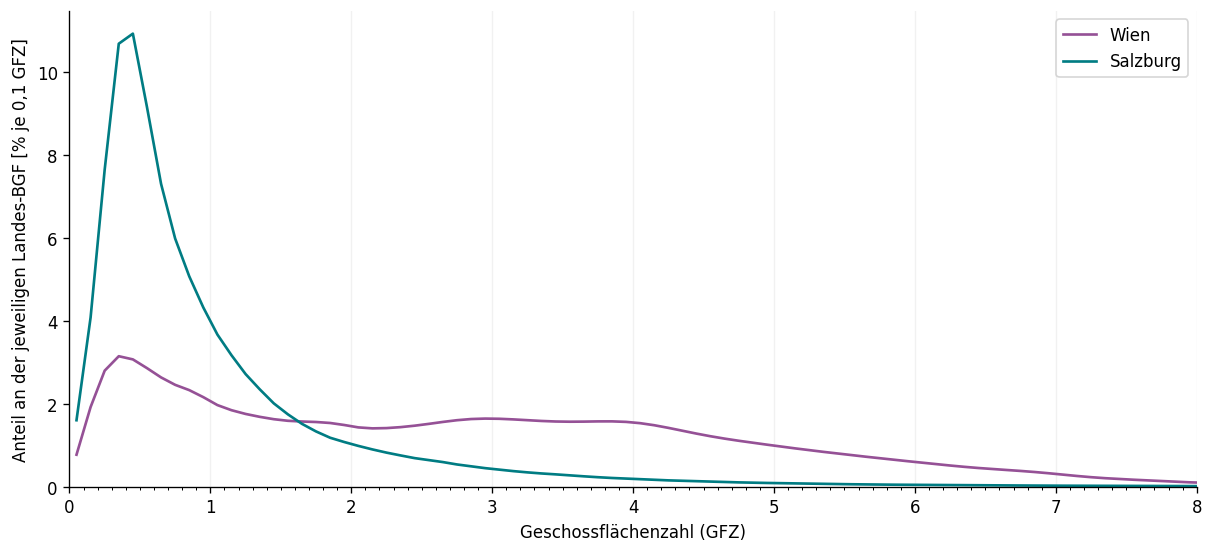

In [21]:
#| label: fig-gfz-wien-salzburg
#| fig-cap: "Vergleich der statistisch hochgerechneten GFZ-Flächenverteilungen von Wien und Salzburg. Jede Landeskurve ist auf die vollständige Landes-BGF im GFZ-Raster bis 20 normiert."
#| fig-width: 10
#| fig-height: 4.5
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
for region, color in [("Wien", "#955196"), ("Salzburg", "#007c83")]:
    reg = by_province.loc[by_province.Bundesland == region].sort_values("GFZ")
    y = 100 * reg.BGF_m2 / reg.BGF_m2.sum()
    ax.plot(reg.GFZ, y, label=region, color=color, linewidth=1.6)
ax.set(xlim=(0, PLOT_GFZ_MAX), ylim=(0, None),
       xlabel="Geschossflächenzahl (GFZ)",
       ylabel="Anteil an der jeweiligen Landes-BGF [% je 0,1 GFZ]")
ax.xaxis.set_major_locator(MultipleLocator(1))
ax.xaxis.set_minor_locator(MultipleLocator(GFZ_STEP))
ax.grid(axis="x", alpha=.17)
ax.legend()
fig.savefig(OUT / "gfz_wien_salzburg.png", dpi=180, bbox_inches="tight")
plt.show()

## 9. Export und Reproduzierbarkeit

Die Ergebnisse werden direkt aus den Notebook-Tabellen gespeichert. Die Datei `gfz_distribution_by_province_use_storeys.csv` enthält die vollständige Verteilung je Zielkombination; `allocation_audit.csv` protokolliert jede Zielgruppe, die Referenz und die Bilanz; die aggregierten CSV-Dateien speisen die Abbildungen.

In [18]:
# CSV-Ausgaben zur Nachnutzung im Hintergrundbericht
(detail.to_csv(OUT / "gfz_distribution_by_province_use_storeys.csv", index=False))
(audit.to_csv(OUT / "allocation_audit.csv", index=False))
(by_province.to_csv(OUT / "gfz_distribution_by_province.csv", index=False))
(at_by_use.to_csv(OUT / "gfz_distribution_austria_by_use.csv", index=False))
(coverage.to_csv(OUT / "reference_coverage.csv", index=False))
(stats_province.reset_index().to_csv(OUT / "statistik_flaechen_bundeslaender.csv", index=False))

report = {
    "description": "GFZ Österreich 2021 – vollständige Notebook-Rechnung",
    "gfz_step": GFZ_STEP, "gfz_max": GFZ_MAX, "ngf_per_bgf": NGF_PER_BGF,
    "method": METHOD, "fallback": FALLBACK, "min_samples": MIN_SAMPLES,
    "n_positive_statistical_cells": int(len(coverage)),
    "n_fallback_cells": int(fallback_mask.sum()),
    "fallback_bgf_m2": fallback_area,
    "fallback_share_of_total_bgf": fallback_area / national_target,
    "statistics_ngf_total_m2": float(control_at.sum()),
    "statistics_bgf_total_m2": national_target,
    "allocated_bgf_m2": national_allocated,
    "total_allocation_residual_m2": national_allocated - national_target,
    "mean_gfz_area_weighted": mean_gfz,
    "reference_input_files": {"buildings": str(BUILDINGS), "statistics": str(STATISTICS)},
    "input_sha256": {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                     for p in (BUILDINGS, STATISTICS)},
}
(OUT / "validation.json").write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")
print("Ausgabeordner:", OUT.resolve())
print("CSV-, PNG- und validation.json-Dateien gespeichert.")

Ausgabeordner: C:\Users\schneids\code\peq-higrube\peq-higrube\Berechnungen\gfz_at\outputs\recalculated
CSV-, PNG- und validation.json-Dateien gespeichert.


## 10. Methodische Einordnung und Einschränkungen

- **Stichprobenübertragung:** Salzburg repräsentiert im aktuellen Modell acht Bundesländer, Wien ausschließlich Wien. Unterschiede innerhalb und zwischen den Ländern können in der Stichprobe unzureichend erfasst sein.
- **Flächenumrechnung:** Das konstante NGF/BGF-Verhältnis von 0,8 beeinflusst die absolute BGF sämtlicher statistischer Zielgruppen. Es wird nicht nutzungs- oder regionalspezifisch kalibriert.
- **KDE:** Scott-Bandbreite, begrenzter GFZ-Bereich 0–20, diskrete 0,1-Schritte und Ersatzreferenzen beeinflussen die Dichteform. Die Normierung garantiert die Flächenerhaltung, **nicht** die empirische Richtigkeit jeder Kurve. Bei identischen GFZ wird eine ausdrücklich gekennzeichnete Histogrammverteilung verwendet.
- **Abdeckung:** Gering besetzte Nutzung-/Geschosskombinationen werden nach der dokumentierten Ersatzhierarchie abgebildet. Die Anzahl der Ersatzkombinationen und ihr Flächenanteil sind getrennt zu interpretieren.
- **Modellgegenstand:** Die ermittelte GFZ-Verteilung ist eine flächengewichtete modellierte Verteilung des *Bestands 2021*, keine flurstücksweise Vermessung des gesamten österreichischen Gebäudebestands. 
